In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## AUDIO DATASET

In [4]:
import os, hashlib, zipfile, subprocess
from pathlib import Path
from collections import Counter
import pandas as pd

DATA = Path("/kaggle/working/soundwel")
DATA.mkdir(parents=True, exist_ok=True)

# file name -> (download link, expected MD5 from the Zenodo page)
FILES = {
    "soundwel.zip": (
        "https://zenodo.org/records/8252482/files/Soundwel%20Dataset%20-%20Audio%20and%20Spectrograms.zip?download=1",
        "dc2144fd683a7c9b27246d51817db9b4"),
    "SoundwelDatasetKey.xlsx": (
        "https://zenodo.org/records/8252482/files/SoundwelDatasetKey.xlsx?download=1",
        "2f87e52a9b28c18e570ac6aae5fb27b9"),
}

def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

# download once, then check the file is not corrupted
for name, (url, expected) in FILES.items():
    out = DATA / name
    if not out.exists():
        subprocess.run(["wget", "-q", "-O", str(out), url], check=True)
    got = md5(out)
    status = "OK" if got == expected else f"MISMATCH ({got})"
    print(f"{name}: {out.stat().st_size / 1e6:.1f} MB, md5 {status}")

# unzip
raw = DATA / "raw"
if not raw.exists():
    with zipfile.ZipFile(DATA / "soundwel.zip") as z:
        z.extractall(raw)

# show the folder structure (2 levels deep) with file types and a few examples
print("\nFolder structure:")
for root, dirs, files in os.walk(raw):
    depth = len(Path(root).relative_to(raw).parts)
    if depth <= 2:
        exts = dict(Counter(Path(f).suffix.lower() for f in files))
        print("  " * depth + f"{Path(root).name}/  files={len(files)} {exts}")
        for f in sorted(files)[:3]:
            print("  " * (depth + 1) + f)

# look at the label key file
xl = pd.ExcelFile(DATA / "SoundwelDatasetKey.xlsx")
print("\nSheets:", xl.sheet_names)
key = xl.parse(xl.sheet_names[0])
print("Shape:", key.shape)
print(key.dtypes)
display(key.head(10))

# columns with few unique values are likely labels (valence, context, etc.)
for c in key.columns:
    n = key[c].nunique()
    if n <= 25:
        print(f"\n{c} ({n} unique):")
        print(key[c].value_counts())

soundwel.zip: 326.4 MB, md5 OK
SoundwelDatasetKey.xlsx: 1.7 MB, md5 OK

Folder structure:
raw/  files=0 {}
  __MACOSX/  files=0 {}
    Soundwel Dataset - Audio and Spectrograms/  files=1 {'.png': 1}
      ._IASPIASPShortPr36Sele2isolaceM1396.wav_spec.png
  Soundwel Dataset - Audio and Spectrograms/  files=13775 {'.wav': 6887, '.png': 6888}
    ._IASPIASPShortPr36Sele2isolaceM1396.wav_spec.png
    ETHZETHZIsolationIsolationpig151.wav
    ETHZETHZIsolationIsolationpig151.wav_spec.png

Sheets: ['Sheet1']
Shape: (6887, 31)
Recording Team                  object
Recording Date          datetime64[ns]
Audio Filename                  object
Spectrogram Filename            object
Age Category                    object
Age Cat NB                     float64
Sex                             object
Context                         object
Context Category                object
Call Type (Freq)                object
Call Type NB                   float64
Valence                         object
F0Mean 

,Recording Team,Recording Date,Audio Filename,Spectrogram Filename,Age Category,Age Cat NB,Sex,Context,Context Category,Call Type (Freq),...,Harmonicity,WienEntrMean,DFMin,LPC1,LPC2,LPC3,LPC4,LPC5,LPC6,Type
0,ETHZ,2014-08-25,ETHZETHZPositivePositivepig1510.wav,ETHZETHZPositivePositivepig1510.wav_spec.png,Weaner,2.0,male,Enriched,Enriched,LFs,...,-0.03,-1.421,1664.488,391.943,958.805,2149.773,3380.637,3859.119,5315.941,LF
1,ETHZ,2014-08-25,ETHZETHZPositivePositivepig1513.wav,ETHZETHZPositivePositivepig1513.wav_spec.png,Weaner,2.0,male,Enriched,Enriched,LFs,...,-0.89,-1.732,1071.457,1038.448,2195.270,3373.159,5547.741,6846.378,7874.259,LF
2,ETHZ,2014-08-25,ETHZETHZPositivePositivepig1514.wav,ETHZETHZPositivePositivepig1514.wav_spec.png,Weaner,2.0,male,Enriched,Enriched,LFs,...,-1.77,-1.277,1223.329,405.034,2224.366,3342.285,3906.131,6044.269,6868.060,LF
3,ETHZ,2014-08-25,ETHZETHZPositivePositivepig1515.wav,ETHZETHZPositivePositivepig1515.wav_spec.png,Weaner,2.0,male,Enriched,Enriched,LFm,...,1.05,-2.217,1101.899,390.746,1174.710,2434.260,3508.924,3855.396,6174.135,LF
4,ETHZ,2014-08-25,ETHZETHZPositivePositivepig1516.wav,ETHZETHZPositivePositivepig1516.wav_spec.png,Weaner,2.0,male,Enriched,Enriched,LFs,...,0.48,-1.324,891.086,369.364,1167.424,2252.133,3095.539,3849.726,4707.992,LF
5,ETHZ,2014-08-25,ETHZETHZPositivePositivepig154.wav,ETHZETHZPositivePositivepig154.wav_spec.png,Weaner,2.0,male,Enriched,Enriched,LFs,...,0.22,-1.457,950.183,400.752,1143.010,2340.624,3883.149,5097.133,6159.800,LF
6,ETHZ,2014-08-25,ETHZETHZPositivePositivepig157.wav,ETHZETHZPositivePositivepig157.wav_spec.png,Weaner,2.0,male,Enriched,Enriched,LFs,...,1.20,-1.506,1009.966,391.185,1148.065,2246.768,3335.790,3865.889,4644.518,LF
7,ETHZ,2014-08-25,ETHZETHZPositivePositivepig158.wav,ETHZETHZPositivePositivepig158.wav_spec.png,Weaner,2.0,male,Enriched,Enriched,LFs,...,0.63,-2.372,1037.249,413.956,1084.897,2340.339,3447.093,5376.911,6326.450,LF
8,ETHZ,2014-08-25,ETHZETHZPositivePositivepig159.wav,ETHZETHZPositivePositivepig159.wav_spec.png,Weaner,2.0,male,Enriched,Enriched,LFs,...,0.04,-1.381,1726.442,362.914,1024.897,2319.630,3429.013,3859.128,6353.485,LF
9,ETHZ,2014-08-26,ETHZETHZPositivePositivepig1610.wav,ETHZETHZPositivePositivepig1610.wav_spec.png,Weaner,2.0,female,Enriched,Enriched,LFs,...,0.67,-2.001,978.419,444.281,2452.255,3408.550,4160.054,4842.919,5823.054,LF



Recording Team (6 unique):
Recording Team
IASPA    2406
NMBU     1418
FBN      1349
IASPB     696
ETHZ      551
IASPC     467
Name: count, dtype: int64

Age Category (3 unique):
Age Category
Piglet         3569
Weaner         1900
GrFinishing    1418
Name: count, dtype: int64

Age Cat NB (3 unique):
Age Cat NB
1.0    3569
2.0    1900
3.0     681
Name: count, dtype: int64

Sex (2 unique):
Sex
female    3316
male      2529
Name: count, dtype: int64

Context (18 unique):
Context
LongIsolation           1553
ShortIsolation          1085
Restrain                 927
Run                      737
Barren                   585
ShortReunion             354
Enriched                 336
NovelObject              333
Castration               295
Crushing                 146
NegativeConditioning     119
PositiveConditioning     119
AfterNursing              79
Huddling                  74
Fighting                  57
MissedNursing             45
BeforeNursing             26
Surprise                 

In [5]:
import numpy as np
import soundfile as sf
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

AUDIO_DIR = raw / "Soundwel Dataset - Audio and Spectrograms"

df = key.copy()
df.columns = [c.strip() for c in df.columns]          # headers may have trailing spaces
for c in ["Recording Team", "Audio Filename", "Spectrogram Filename", "Valence", "Context Category"]:
    df[c] = df[c].astype(str).str.strip()

# link each row to its files and check they exist
df["wav_path"] = df["Audio Filename"].map(lambda f: AUDIO_DIR / f)
df["png_path"] = df["Spectrogram Filename"].map(lambda f: AUDIO_DIR / f)
df["wav_ok"] = df["wav_path"].map(lambda p: p.exists())
df["png_ok"] = df["png_path"].map(lambda p: p.exists())
print("missing wav:", (~df.wav_ok).sum(), "| missing png:", (~df.png_ok).sum())
if (~df.wav_ok | ~df.png_ok).any():
    display(df.loc[~df.wav_ok | ~df.png_ok, ["Audio Filename", "Spectrogram Filename"]].head())
df = df[df.wav_ok & df.png_ok].reset_index(drop=True)

# label: 1 = negative (distress), 0 = positive
df["label"] = (df["Valence"] == "Neg").astype(int)

# session = one team on one day; used as the group for splitting
df["session"] = df["Recording Team"] + "_" + df["Recording Date"].astype(str)

# audio properties (reads file headers only, so it is fast)
info = [sf.info(str(p)) for p in df["wav_path"]]
df["sr"] = [i.samplerate for i in info]
df["channels"] = [i.channels for i in info]
df["duration_s"] = [i.duration for i in info]
print("\nSample rates:\n", df["sr"].value_counts())
print("\nChannels:\n", df["channels"].value_counts())
print("\nDuration (s):\n", df["duration_s"].describe().round(3))

# size of the provided spectrogram images (check a sample)
sizes = Counter(Image.open(p).size for p in df["png_path"].sample(50, random_state=0))
print("\nSpectrogram image sizes (sample of 50):", dict(sizes))

# confound checks
print("\nTeam x Valence:")
display(pd.crosstab(df["Recording Team"], df["Valence"], margins=True))
print("Context x Valence:")
display(pd.crosstab(df["Context Category"], df["Valence"]))
print("Number of sessions:", df["session"].nunique())
print("Sessions containing only one valence:",
      (df.groupby("session")["Valence"].nunique() == 1).sum())

# session-grouped, label-stratified split: ~70% train / 15% val / 15% test
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
df["fold"] = -1
for k, (_, idx) in enumerate(sgkf.split(df, df["label"], groups=df["session"])):
    df.loc[idx, "fold"] = k
df["split"] = np.where(df["fold"] == 0, "test", np.where(df["fold"] == 1, "val", "train"))

print("\nSplit x Valence:")
display(pd.crosstab(df["split"], df["Valence"], margins=True))
assert df.groupby("session")["split"].nunique().max() == 1, "a session leaked across splits"
print("No session appears in more than one split.")

df.to_csv(DATA / "soundwel_meta.csv", index=False)
print("Saved", DATA / "soundwel_meta.csv")

missing wav: 0 | missing png: 0

Sample rates:
 sr
44100    6887
Name: count, dtype: int64

Channels:
 channels
1    6887
Name: count, dtype: int64

Duration (s):
 count    6887.000
mean        0.352
std         0.282
min         0.043
25%         0.181
50%         0.277
75%         0.428
max         3.595
Name: duration_s, dtype: float64

Spectrogram image sizes (sample of 50): {(875, 656): 50}

Team x Valence:


Valence,Neg,Pos,All
Recording Team,,,
ETHZ,311,240,551
FBN,1230,119,1349
IASPA,1979,427,2406
IASPB,0,696,696
IASPC,467,0,467
NMBU,585,833,1418
All,4572,2315,6887


Context x Valence:


Valence,Neg,Pos
Context Category,,
AfterNursing,0,79
Barren,585,0
BeforeNursing,0,26
Castration,295,0
Crushing,146,0
Enriched,0,336
Fighting,57,0
Huddling,0,74
Isolation,2048,0


Number of sessions: 43
Sessions containing only one valence: 22

Split x Valence:


Valence,Neg,Pos,All
split,,,
test,166,0,166
train,4111,1493,5604
val,295,822,1117
All,4572,2315,6887


No session appears in more than one split.
Saved /kaggle/working/soundwel/soundwel_meta.csv


**Neg**: Barren · GrFinishing · LFs · 0.28 s

Normal speed (×3):

Half speed (lower pitch, easier to hear):

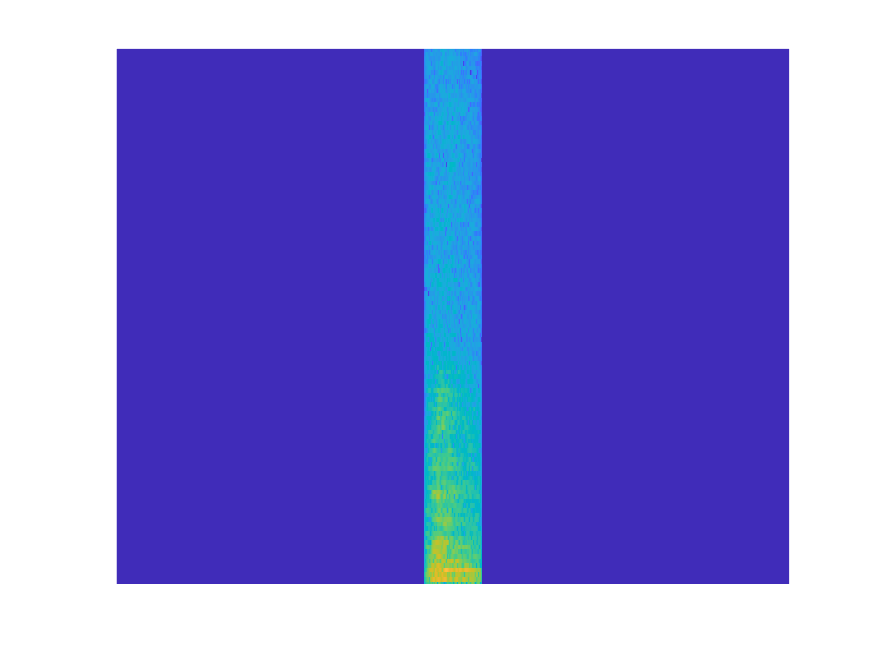

**Neg**: Isolation · Piglet · LFm · 0.28 s

Normal speed (×3):

Half speed (lower pitch, easier to hear):

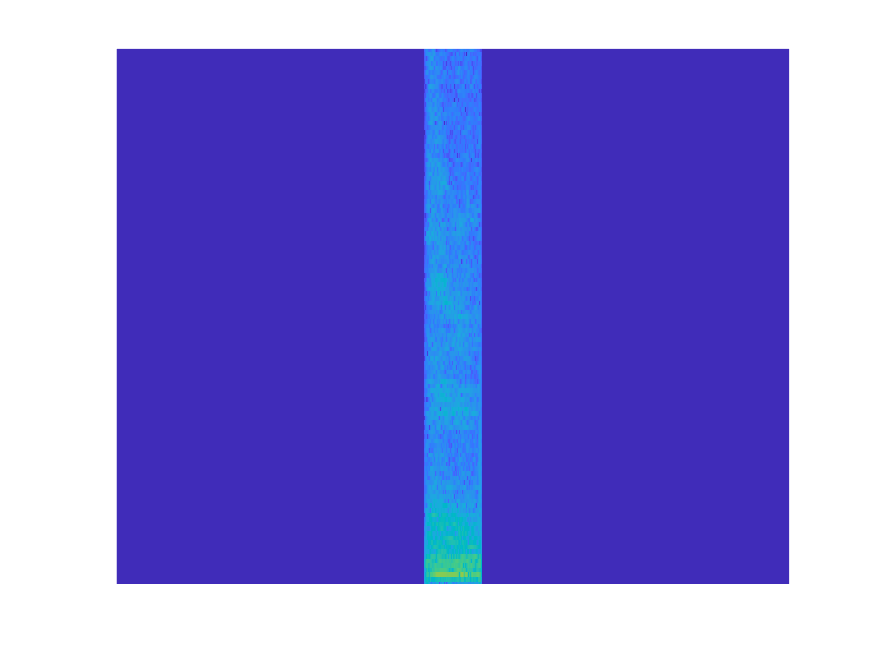

**Neg**: Isolation · Piglet · Mixed · 0.22 s

Normal speed (×3):

Half speed (lower pitch, easier to hear):

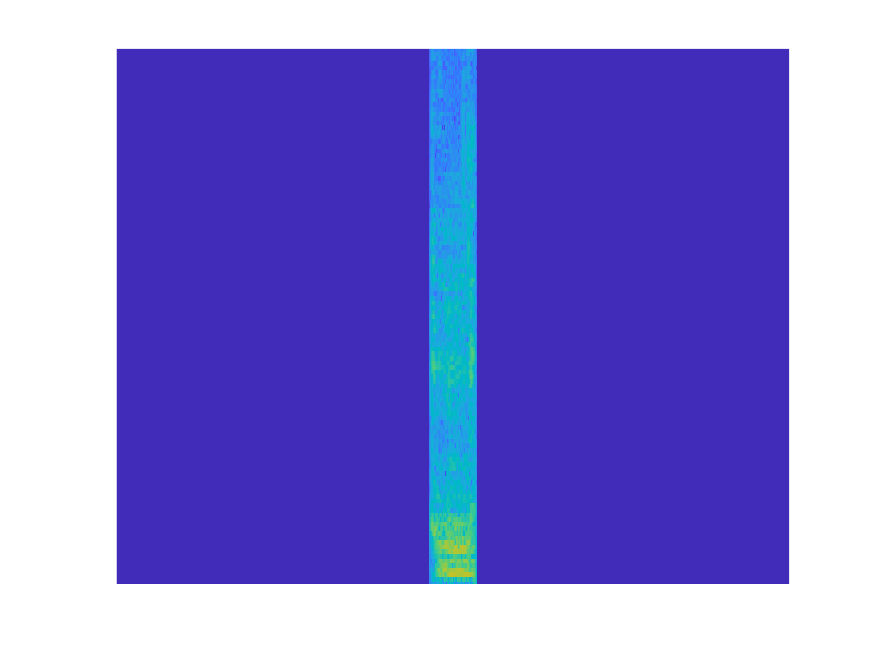

**Pos**: PositiveConditioning · Weaner · LFs · 0.36 s

Normal speed (×3):

Half speed (lower pitch, easier to hear):

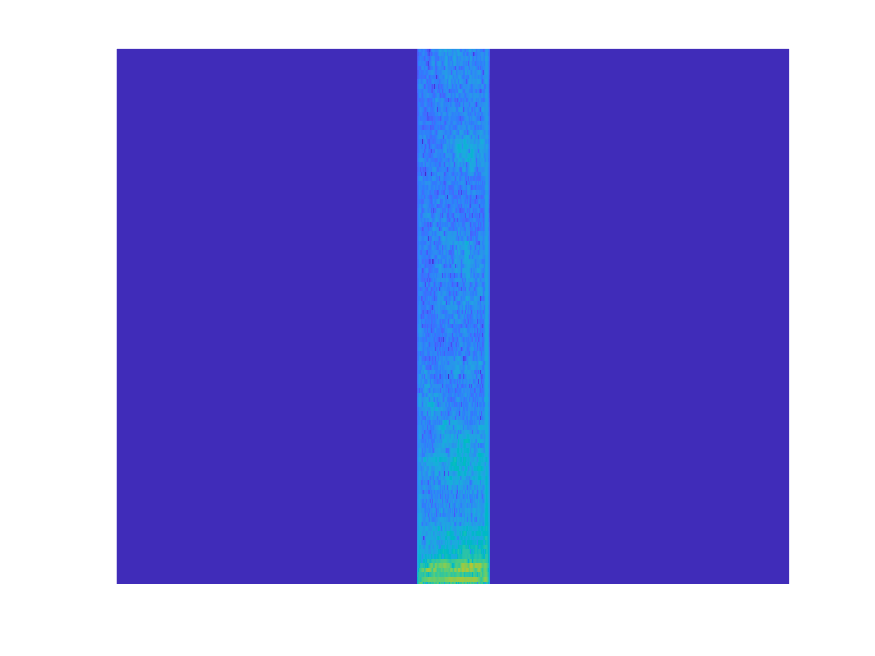

**Pos**: Run · GrFinishing · nan · 0.23 s

Normal speed (×3):

Half speed (lower pitch, easier to hear):

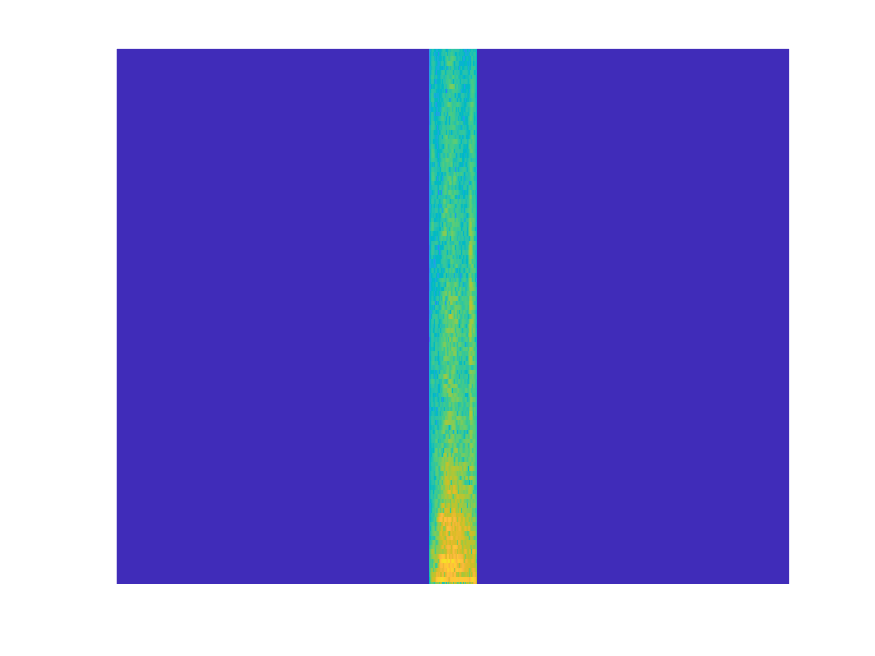

**Pos**: Enriched · Weaner · LFs · 0.22 s

Normal speed (×3):

Half speed (lower pitch, easier to hear):

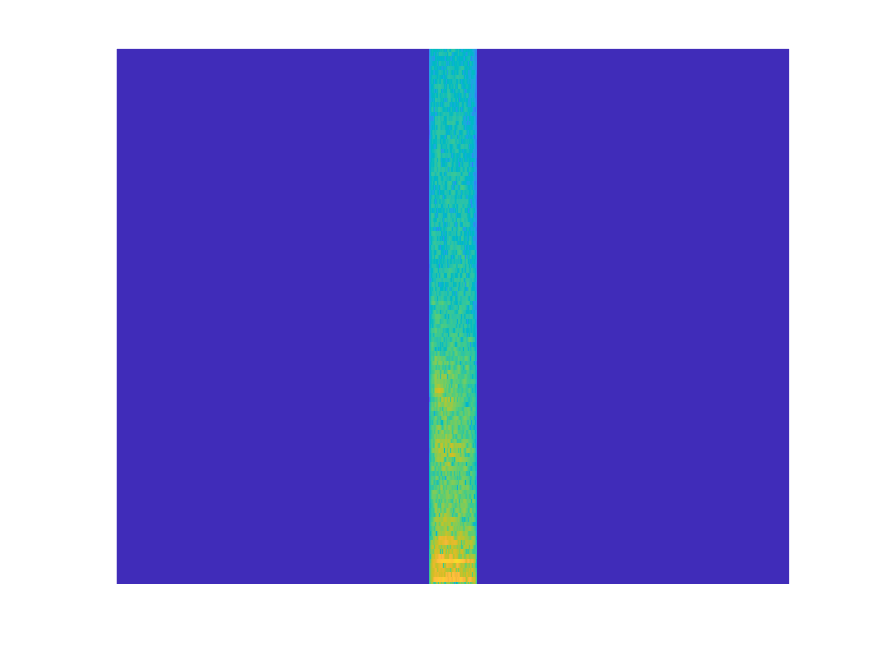

In [6]:
import soundfile as sf
from IPython.display import Audio, Image as IImage, display, Markdown

AUDIO_DIR = raw / "Soundwel Dataset - Audio and Spectrograms"
k = key.copy()
k.columns = [c.strip() for c in k.columns]

def playable(path, repeats=3, pad_s=0.5):
    wav, sr = sf.read(str(path), dtype="float32")
    if wav.ndim > 1:
        wav = wav.mean(axis=1)
    wav = wav / (np.abs(wav).max() + 1e-9) * 0.9          # normalise volume
    gap = np.zeros(int(pad_s * sr), dtype="float32")
    clip = np.concatenate([gap] + [np.concatenate([wav, gap]) for _ in range(repeats)])
    return clip, sr, len(wav) / sr

for val in ["Neg", "Pos"]:
    sample = k[k["Valence"].astype(str).str.strip() == val].sample(3, random_state=1)
    for _, r in sample.iterrows():
        clip, sr, dur = playable(AUDIO_DIR / r["Audio Filename"].strip())
        display(Markdown(f"**{val}**: {r['Context Category']} · {r['Age Category']} · "
                         f"{r['Call Type (Freq)']} · {dur:.2f} s"))
        display(Markdown("Normal speed (×3):"))
        display(Audio(clip, rate=sr))
        display(Markdown("Half speed (lower pitch, easier to hear):"))
        display(Audio(clip, rate=sr // 2))
        display(IImage(filename=str(AUDIO_DIR / r["Spectrogram Filename"].strip()), width=400))

In [7]:
display(df.sort_values("duration_s", ascending=False)[["Audio Filename", "Context Category", "Valence", "duration_s"]].head(10))

,Audio Filename,Context Category,Valence,duration_s
1770,FBNFBNRestrain05022015VT10HFs6.wav,Restrain,Neg,3.594626
1805,FBNFBNRestrain05022015VT18HFs5.wav,Restrain,Neg,2.929342
6762,NMBUNMBUTransit (613).wav,Run,Pos,2.840340
1790,FBNFBNRestrain05022015VT14HFs2.wav,Restrain,Neg,2.796213
1769,FBNFBNRestrain05022015VT10HFs5.wav,Restrain,Neg,2.709887
1793,FBNFBNRestrain05022015VT14HFs5.wav,Restrain,Neg,2.618662
6413,NMBUNMBUTransit (264).wav,Run,Pos,2.537075
1813,FBNFBNRestrain05022015VT5HFs1.wav,Restrain,Neg,2.474399
1791,FBNFBNRestrain05022015VT14HFs3.wav,Restrain,Neg,2.452222
1838,FBNFBNRestrain09042015VT4HFs3.wav,Restrain,Neg,2.396735


In [8]:
from sklearn.model_selection import StratifiedKFold

N_FOLDS = 5
overall_pos = (df["label"] == 0).mean()

def grouped_folds(seed):
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    f = np.full(len(df), -1)
    for k, (_, idx) in enumerate(sgkf.split(df, df["label"], groups=df["session"])):
        f[idx] = k
    return f

def balance(f):
    # worst gap between a fold's share of positive calls and the overall share
    gaps = [abs((df["label"][f == k] == 0).mean() - overall_pos) for k in range(N_FOLDS)]
    sizes = [(f == k).sum() for k in range(N_FOLDS)]
    return max(gaps), min(sizes)

# try many seeds, keep the most balanced folds (chosen before any training)
best = min(range(500), key=lambda s: (round(balance(grouped_folds(s))[0], 3), -balance(grouped_folds(s))[1]))
df["cv_fold"] = grouped_folds(best)
gap, smallest = balance(df["cv_fold"].values)
print(f"Chosen seed {best}: worst positive-share gap {gap:.3f}, smallest fold {smallest} calls")

print("\nFold x Valence:")
display(pd.crosstab(df["cv_fold"], df["Valence"], margins=True))
print("Fold x Team:")
display(pd.crosstab(df["cv_fold"], df["Recording Team"]))
assert df.groupby("session")["cv_fold"].nunique().max() == 1, "a session leaked across folds"

# random split (ignores sessions), only used to measure leakage
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
df["random_fold"] = -1
for k, (_, idx) in enumerate(skf.split(df, df["label"])):
    df.loc[idx, "random_fold"] = k

# teams with both valences, for leave-one-team-out
mixed_teams = [t for t, g in df.groupby("Recording Team") if g["Valence"].nunique() == 2]
print("Teams usable for leave-one-team-out:", mixed_teams)

df = df.drop(columns=["fold", "split"], errors="ignore")
df.to_csv(DATA / "soundwel_meta.csv", index=False)
print("Saved", DATA / "soundwel_meta.csv")

Chosen seed 230: worst positive-share gap 0.140, smallest fold 187 calls

Fold x Valence:


Valence,Neg,Pos,All
cv_fold,,,
0,1949,741,2690
1,1152,514,1666
2,441,137,578
3,925,841,1766
4,105,82,187
All,4572,2315,6887


Fold x Team:


Recording Team,ETHZ,FBN,IASPA,IASPB,IASPC,NMBU
cv_fold,,,,,,
0,0,223,1287,696,324,160
1,0,137,1115,0,77,337
2,227,281,4,0,66,0
3,137,708,0,0,0,921
4,187,0,0,0,0,0


Teams usable for leave-one-team-out: ['ETHZ', 'FBN', 'IASPA', 'NMBU']
Saved /kaggle/working/soundwel/soundwel_meta.csv


In [9]:
# how big are the sessions, and are dates missing?
print("Rows with no recording date:", df["Recording Date"].isna().sum())
print("\nMissing dates per team:")
print(df.groupby("Recording Team")["Recording Date"].apply(lambda s: s.isna().sum()))

sess = df.groupby("session").agg(n=("label", "size"),
                                 pos_share=("label", lambda s: round((s == 0).mean(), 2)),
                                 team=("Recording Team", "first"))
print("\nLargest sessions:")
display(sess.sort_values("n", ascending=False).head(12))
print("Session size summary:\n", sess["n"].describe().round(1))

# filename patterns per team, to see if a pig ID can be parsed for a finer split
for team, g in df.groupby("Recording Team"):
    print(f"\n{team}:")
    for f in g["Audio Filename"].sample(min(6, len(g)), random_state=0):
        print("   ", f)
        

Rows with no recording date: 737

Missing dates per team:
Recording Team
ETHZ       0
FBN        0
IASPA      0
IASPB      0
IASPC      0
NMBU     737
Name: Recording Date, dtype: int64

Largest sessions:


,n,pos_share,team
session,,,
IASPA_2011-01-01,1287,0.00,IASPA
IASPA_2008-01-01,1115,0.38,IASPA
NMBU_NaT,737,1.00,NMBU
IASPB_2011-01-01,696,1.00,IASPB
IASPC_2011-04-26,324,0.00,IASPC
FBN_2014-05-01,212,0.00,FBN
FBN_2014-05-05,169,0.00,FBN
FBN_2014-03-20,166,0.00,FBN
NMBU_2017-06-07,153,0.06,NMBU


Session size summary:
 count      43.0
mean      160.2
std       276.8
min         1.0
25%        36.0
50%        77.0
75%       120.5
max      1287.0
Name: n, dtype: float64

ETHZ:
    ETHZETHZPositivePositivepig2515.wav
    ETHZETHZIsolationIsolationpig344.wav
    ETHZETHZPositivePositivepig267.wav
    ETHZETHZPositivePositivepig3616.wav
    ETHZETHZPositivePositivepig3224.wav
    ETHZETHZPositivePositivepig208.wav

FBN:
    FBNFBNNovelObject01052014VT6HFs2.wav
    FBNFBNIsolation24032014VT2LFs2.wav
    FBNFBNOpenField20032014VT7HFs1.wav
    FBNFBNRestrain09042015VT1LFs4.wav
    FBNFBNNovelObject20032014VT5HFm6.wav
    FBNFBNIsolation14042014VT8HFs2.wav

IASPA:
    IASPIASPArmsArmsSow13Pig219.wav
    IASPIASPReunionReunSow92Pig611.wav
    IASPIASPBacktests99p0108lflow28.wav
    IASPIASPReunionReunSow6Pig1118.wav
    IASPIASPShortPr55Sele1isolace1179.wav
    IASPIASPShortPr55Sele6isolace21126.wav

IASPB:
    IASPIASPShortPr67Sele03Na3min1.wav
    IASPIASPShortPr39Sele08Na3min6.wav
   

In [10]:
rng = np.random.default_rng(0)

# one row per session: size and number of positive calls
g = df.groupby("session").agg(n=("label", "size"), pos=("label", lambda s: (s == 0).sum()))
sessions, n, pos = g.index.to_numpy(), g["n"].to_numpy(), g["pos"].to_numpy()
target_share = pos.sum() / n.sum()

def cost(assign):
    sizes = np.bincount(assign, weights=n, minlength=N_FOLDS)
    poss = np.bincount(assign, weights=pos, minlength=N_FOLDS)
    if (sizes < 800).any():                                     # every fold needs at least 800 calls
        return np.inf
    share_gap = np.abs(poss / sizes - target_share).max()      # class balance comes first
    size_gap = (sizes.max() - sizes.min()) / sizes.mean()      # size balance is a tie-breaker
    return share_gap + 0.05 * size_gap

# local search: start from random assignments, move sessions between folds while it helps
best_assign, best_cost = None, np.inf
for restart in range(200):
    a = rng.integers(0, N_FOLDS, len(sessions))
    c = cost(a)
    improved = True
    while improved:
        improved = False
        for i in rng.permutation(len(sessions)):
            for k in range(N_FOLDS):
                if k == a[i]:
                    continue
                old, a[i] = a[i], k
                c_new = cost(a)
                if c_new < c - 1e-9:
                    c, improved = c_new, True
                else:
                    a[i] = old
    if c < best_cost:
        best_cost, best_assign = c, a.copy()

df["cv_fold"] = df["session"].map(dict(zip(sessions, best_assign)))

summary = df.groupby("cv_fold").agg(calls=("label", "size"),
                                    pos_share=("label", lambda s: round((s == 0).mean(), 3)),
                                    sessions=("session", "nunique"))
print(f"Overall positive share: {target_share:.3f}")
display(summary)
print("Fold x Team:")
display(pd.crosstab(df["cv_fold"], df["Recording Team"]))
assert df.groupby("session")["cv_fold"].nunique().max() == 1, "a session leaked across folds"
print("No session appears in more than one fold.")

df.to_csv(DATA / "soundwel_meta.csv", index=False)
print("Saved", DATA / "soundwel_meta.csv")

Overall positive share: 0.336


,calls,pos_share,sessions
cv_fold,,,
0,817,0.250,11
1,1353,0.324,5
2,869,0.252,9
3,1983,0.351,2
4,1865,0.406,16


Fold x Team:


Recording Team,ETHZ,FBN,IASPA,IASPB,IASPC,NMBU
cv_fold,,,,,,
0,104,232,0,0,324,157
1,0,169,1119,0,0,65
2,447,196,0,0,0,226
3,0,0,1287,696,0,0
4,0,752,0,0,143,970


No session appears in more than one fold.
Saved /kaggle/working/soundwel/soundwel_meta.csv


In [11]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score

FEATS = ["F0Mean", "Q25", "Q50", "Q75", "Fpeak", "Dur", "AMVar", "AMRate", "AMExtent",
         "Harmonicity", "WienEntrMean", "DFMin", "LPC1", "LPC2", "LPC3", "LPC4", "LPC5", "LPC6"]
missing = df[FEATS].isna().sum()
print("Features with missing values:\n", missing[missing > 0] if (missing > 0).any() else "none")

X = df[FEATS].to_numpy()
y = df["label"].to_numpy()          # 1 = negative valence (distress)

def make_models():
    return {
        "LogReg": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                LogisticRegression(max_iter=2000, class_weight="balanced")),
        "HistGB": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                 class_weight="balanced", random_state=0),
    }

def scores(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {"macro_f1": f1_score(y_true, pred, average="macro"),
            "bal_acc": balanced_accuracy_score(y_true, pred),
            "auc": roc_auc_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan}

def evaluate(scheme, splits):
    rows = []
    for fold_name, train, test in splits:
        for model_name, model in make_models().items():
            model.fit(X[train], y[train])
            prob = model.predict_proba(X[test])[:, 1]
            rows.append({"scheme": scheme, "fold": fold_name, "model": model_name, **scores(y[test], prob)})
    return pd.DataFrame(rows)

cv, rf, team = df["cv_fold"].to_numpy(), df["random_fold"].to_numpy(), df["Recording Team"].to_numpy()
grouped_splits = [(k, cv != k, cv == k) for k in range(N_FOLDS)]
random_splits  = [(k, rf != k, rf == k) for k in range(N_FOLDS)]
team_splits    = [(t, team != t, team == t) for t in mixed_teams]

res = pd.concat([evaluate("grouped CV", grouped_splits),
                 evaluate("random CV", random_splits),
                 evaluate("leave-one-team-out", team_splits)], ignore_index=True)

print("\nMean ± std across folds:")
display(res.groupby(["scheme", "model"])[["macro_f1", "bal_acc", "auc"]].agg(["mean", "std"]).round(3))

print("Macro-F1 per fold, grouped CV:")
display(res[res["scheme"] == "grouped CV"].pivot(index="fold", columns="model", values="macro_f1").round(3))
print("Macro-F1 per held-out team:")
display(res[res["scheme"] == "leave-one-team-out"].pivot(index="fold", columns="model", values="macro_f1").round(3))

res.to_csv(DATA / "results_acoustic_baseline.csv", index=False)

Features with missing values:
 F0Mean          3163
Q25              737
Q50              737
Q75              737
Fpeak            737
Dur              737
AMVar            817
AMRate           927
AMExtent         927
Harmonicity      737
WienEntrMean     737
DFMin           1530
LPC1            1530
LPC2            1530
LPC3            1530
LPC4            1530
LPC5            1530
LPC6            1530
dtype: int64

Mean ± std across folds:


macro_f1        bal_acc           auc       
                              mean    std    mean    std   mean    std
scheme             model                                              
grouped CV         HistGB    0.598  0.150   0.611  0.101  0.769  0.052
                   LogReg    0.535  0.132   0.558  0.114  0.689  0.066
leave-one-team-out HistGB    0.445  0.184   0.513  0.175  0.558  0.175
                   LogReg    0.442  0.192   0.482  0.198  0.574  0.220
random CV          HistGB    0.892  0.010   0.888  0.011  0.961  0.007
                   LogReg    0.735  0.018   0.773  0.018  0.810  0.010

Macro-F1 per fold, grouped CV:


model,HistGB,LogReg
fold,,
0,0.557,0.542
1,0.729,0.621
2,0.655,0.648
3,0.694,0.550
4,0.356,0.314


Macro-F1 per held-out team:


model,HistGB,LogReg
fold,,
ETHZ,0.392,0.664
FBN,0.464,0.397
IASPA,0.683,0.501
NMBU,0.241,0.205


In [12]:
miss = df[FEATS].isna()
print("Share of missing values by team:")
display(miss.groupby(df["Recording Team"]).mean().round(2))
print("Share of missing values by context (selected features):")
display(miss.groupby(df["Context Category"]).mean()[["F0Mean", "Q25", "DFMin"]].round(2))

def evaluate_X(Xmat, scheme, splits, models, rows_mask=None):
    rows = []
    for fold_name, train, test in splits:
        if rows_mask is not None:
            train, test = train & rows_mask, test & rows_mask
        if len(np.unique(y[test])) < 2 or len(np.unique(y[train])) < 2:
            print(f"  skipped {scheme} fold {fold_name}: only one class")
            continue
        for model_name, model in models().items():
            model.fit(Xmat[train], y[train])
            prob = model.predict_proba(Xmat[test])[:, 1]
            rows.append({"scheme": scheme, "fold": fold_name, "model": model_name,
                         "n_test": int(test.sum()), "pos_test": int((y[test] == 0).sum()),
                         **scores(y[test], prob)})
    return pd.DataFrame(rows)

hgb_only = lambda: {"HistGB": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                                             class_weight="balanced", random_state=0)}

# 1) missingness-only model: does WHICH features are missing predict valence?
Xm = miss.to_numpy().astype(float)
res_miss = pd.concat([evaluate_X(Xm, "random CV", random_splits, hgb_only),
                      evaluate_X(Xm, "grouped CV", grouped_splits, hgb_only)], ignore_index=True)
print("\nMissingness-only model (no feature values at all):")
display(res_miss.groupby("scheme")[["macro_f1", "auc"]].mean().round(3))

# 2) clean baseline: core features only, rows that have them
CORE = ["Q25", "Q50", "Q75", "Fpeak", "Dur", "Harmonicity", "WienEntrMean"]
keep = df[CORE].notna().all(axis=1).to_numpy()
print(f"\nRows with all core features: {keep.sum()} of {len(df)}")
Xc = df[CORE].to_numpy()

res_clean = pd.concat([evaluate_X(Xc, "random CV", random_splits, make_models, keep),
                       evaluate_X(Xc, "grouped CV", grouped_splits, make_models, keep),
                       evaluate_X(Xc, "leave-one-team-out", team_splits, make_models, keep)],
                      ignore_index=True)
print("\nClean baseline (core features, complete rows), mean ± std:")
display(res_clean.groupby(["scheme", "model"])[["macro_f1", "bal_acc", "auc"]].agg(["mean", "std"]).round(3))
print("Per fold (test size and positives shown):")
display(res_clean[res_clean["model"] == "HistGB"][["scheme", "fold", "n_test", "pos_test", "macro_f1", "auc"]].round(3))

res_clean.to_csv(DATA / "results_acoustic_baseline_clean.csv", index=False)

Share of missing values by team:


,F0Mean,Q25,Q50,Q75,Fpeak,Dur,AMVar,AMRate,AMExtent,Harmonicity,WienEntrMean,DFMin,LPC1,LPC2,LPC3,LPC4,LPC5,LPC6
Recording Team,,,,,,,,,,,,,,,,,,
ETHZ,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
FBN,0.24,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.01,0.00,0.00,0.26,0.26,0.26,0.26,0.26,0.26,0.26
IASPA,0.46,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.01,0.00,0.00,0.15,0.15,0.15,0.15,0.15,0.15,0.15
IASPB,0.83,0.00,0.00,0.00,0.00,0.00,0.11,0.23,0.23,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
IASPC,0.79,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.17,0.17,0.17,0.17,0.17,0.17,0.17
NMBU,0.56,0.52,0.52,0.52,0.52,0.52,0.52,0.52,0.52,0.52,0.52,0.52,0.52,0.52,0.52,0.52,0.52,0.52


Share of missing values by context (selected features):


,F0Mean,Q25,DFMin
Context Category,,,
AfterNursing,0.19,0.0,0.47
Barren,0.07,0.0,0.00
BeforeNursing,0.96,0.0,0.04
Castration,0.74,0.0,0.20
Crushing,0.51,0.0,0.26
Enriched,0.04,0.0,0.00
Fighting,0.51,0.0,0.46
Huddling,0.55,0.0,0.11
Isolation,0.32,0.0,0.11



Missingness-only model (no feature values at all):


,macro_f1,auc
scheme,,
grouped CV,0.465,0.614
random CV,0.698,0.770



Rows with all core features: 6150 of 6887

Clean baseline (core features, complete rows), mean ± std:


macro_f1        bal_acc           auc       
                              mean    std    mean    std   mean    std
scheme             model                                              
grouped CV         HistGB    0.629  0.115   0.623  0.112  0.737  0.084
                   LogReg    0.577  0.105   0.612  0.092  0.680  0.117
leave-one-team-out HistGB    0.524  0.112   0.577  0.146  0.651  0.196
                   LogReg    0.507  0.148   0.562  0.178  0.630  0.233
random CV          HistGB    0.833  0.006   0.838  0.009  0.929  0.007
                   LogReg    0.685  0.015   0.744  0.012  0.833  0.006

Per fold (test size and positives shown):


,scheme,fold,n_test,pos_test,macro_f1,auc
1,random CV,0,1261,346,0.826,0.926
3,random CV,1,1220,305,0.843,0.938
5,random CV,2,1218,304,0.836,0.931
7,random CV,3,1222,308,0.831,0.929
9,random CV,4,1229,315,0.831,0.921
11,grouped CV,0,817,204,0.552,0.684
13,grouped CV,1,1353,438,0.757,0.825
15,grouped CV,2,869,219,0.701,0.820
17,grouped CV,3,1983,696,0.661,0.721
19,grouped CV,4,1128,21,0.474,0.635


In [13]:
def assign_folds(mask, restarts=200, seed=0):
    sub = df[mask]
    g = sub.groupby("session").agg(n=("label", "size"), pos=("label", lambda s: (s == 0).sum()))
    ses, n_, p_ = g.index.to_numpy(), g["n"].to_numpy(), g["pos"].to_numpy()
    target = p_.sum() / n_.sum()
    min_size = 0.6 * n_.sum() / N_FOLDS                    # no fold smaller than 60% of an even share

    def c(a):
        sizes = np.bincount(a, weights=n_, minlength=N_FOLDS)
        poss = np.bincount(a, weights=p_, minlength=N_FOLDS)
        if (sizes < min_size).any():
            return np.inf
        return np.abs(poss / sizes - target).max() + 0.05 * (sizes.max() - sizes.min()) / sizes.mean()

    rng = np.random.default_rng(seed)
    best, best_c = None, np.inf
    for _ in range(restarts):
        a = rng.integers(0, N_FOLDS, len(ses))
        cur, improved = c(a), True
        while improved:
            improved = False
            for i in rng.permutation(len(ses)):
                for k in range(N_FOLDS):
                    if k == a[i]:
                        continue
                    old, a[i] = a[i], k
                    new = c(a)
                    if new < cur - 1e-9:
                        cur, improved = new, True
                    else:
                        a[i] = old
        if cur < best_c:
            best_c, best = cur, a.copy()
    assert best is not None, "no valid fold assignment found"
    return dict(zip(ses, best)), target

mapping, target = assign_folds(keep)
df["in_benchmark"] = keep
df["cv_fold_core"] = -1
df.loc[keep, "cv_fold_core"] = df.loc[keep, "session"].map(mapping)

bench = df[keep]
print(f"Benchmark rows: {len(bench)}, overall positive share {target:.3f}")
display(bench.groupby("cv_fold_core").agg(calls=("label", "size"),
                                          pos_share=("label", lambda s: round((s == 0).mean(), 3)),
                                          positives=("label", lambda s: int((s == 0).sum())),
                                          sessions=("session", "nunique")))
display(pd.crosstab(bench["cv_fold_core"], bench["Recording Team"]))
assert bench.groupby("session")["cv_fold_core"].nunique().max() == 1, "a session leaked across folds"

# rerun the clean baseline on the new folds
cvc = df["cv_fold_core"].to_numpy()
grouped_core = [(k, cvc != k, cvc == k) for k in range(N_FOLDS)]
res_core = pd.concat([evaluate_X(Xc, "random CV", random_splits, make_models, keep),
                      evaluate_X(Xc, "grouped CV", grouped_core, make_models, keep),
                      evaluate_X(Xc, "leave-one-team-out", team_splits, make_models, keep)],
                     ignore_index=True)
print("\nBaseline on the benchmark (mean ± std):")
display(res_core.groupby(["scheme", "model"])[["macro_f1", "bal_acc", "auc"]].agg(["mean", "std"]).round(3))
display(res_core[(res_core["model"] == "HistGB") & (res_core["scheme"] == "grouped CV")]
        [["fold", "n_test", "pos_test", "macro_f1", "auc"]].round(3))

df.to_csv(DATA / "soundwel_meta.csv", index=False)
res_core.to_csv(DATA / "results_baseline_benchmark.csv", index=False)

Benchmark rows: 6150, overall positive share 0.257


,calls,pos_share,positives,sessions
cv_fold_core,,,,
0,771,0.201,155,10
1,1661,0.257,427,4
2,2177,0.320,696,8
3,771,0.195,150,9
4,770,0.195,150,11


Recording Team,ETHZ,FBN,IASPA,IASPB,IASPC,NMBU
cv_fold_core,,,,,,
0,249,343,0,0,66,113
1,0,222,1115,0,324,0
2,0,190,1291,696,0,0
3,219,324,0,0,77,151
4,83,270,0,0,0,417



Baseline on the benchmark (mean ± std):


macro_f1        bal_acc           auc       
                              mean    std    mean    std   mean    std
scheme             model                                              
grouped CV         HistGB    0.667  0.077   0.663  0.077  0.753  0.105
                   LogReg    0.605  0.082   0.645  0.088  0.698  0.102
leave-one-team-out HistGB    0.524  0.112   0.577  0.146  0.651  0.196
                   LogReg    0.507  0.148   0.562  0.178  0.630  0.233
random CV          HistGB    0.833  0.006   0.838  0.009  0.929  0.007
                   LogReg    0.685  0.015   0.744  0.012  0.833  0.006

,fold,n_test,pos_test,macro_f1,auc
11,0,771,155,0.698,0.817
13,1,1661,427,0.754,0.844
15,2,2177,696,0.645,0.694
17,3,771,150,0.690,0.816
19,4,770,150,0.547,0.596


Log-mel array: (6887, 64, 101) float16
Calls longer than 1.0 s (centre-cropped): 3.5%
Saved /kaggle/working/soundwel/logmels_32k_64x101.npy


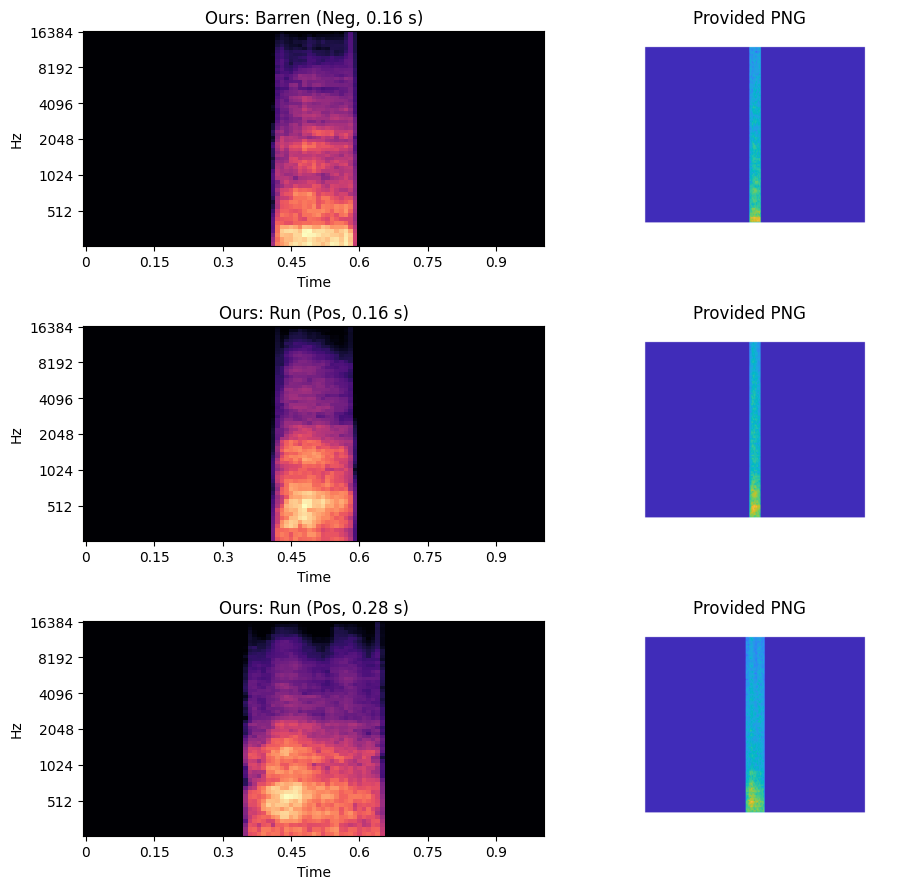

In [14]:
import librosa, librosa.display
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

SR, N_FFT, HOP, N_MELS, FMIN, FMAX, CLIP_S = 32000, 1024, 320, 64, 50, 16000, 1.0
L = int(SR * CLIP_S)

def fix_length(w):
    if len(w) >= L:                                 # longer than 1 s: take the centre
        start = (len(w) - L) // 2
        return w[start:start + L]
    pad = L - len(w)                                # shorter: pad both sides so the call sits in the middle
    return np.pad(w, (pad // 2, pad - pad // 2))

def logmel(path):
    w, _ = librosa.load(str(path), sr=SR, mono=True)
    w = w / (np.abs(w).max() + 1e-9)                # per-clip volume normalisation
    w = fix_length(w)
    m = librosa.feature.melspectrogram(y=w, sr=SR, n_fft=N_FFT, hop_length=HOP,
                                       n_mels=N_MELS, fmin=FMIN, fmax=FMAX, power=2.0)
    return librosa.power_to_db(m, ref=np.max, top_db=80).astype(np.float16)

mels = Parallel(n_jobs=-1)(delayed(logmel)(p) for p in df["wav_path"])
mels = np.stack(mels)
print("Log-mel array:", mels.shape, mels.dtype)
print(f"Calls longer than {CLIP_S} s (centre-cropped): {(df['duration_s'] > CLIP_S).mean():.1%}")

np.save(DATA / "logmels_32k_64x101.npy", mels)
print("Saved", DATA / "logmels_32k_64x101.npy")

# compare our spectrogram with the provided PNG for 3 calls
fig, axes = plt.subplots(3, 2, figsize=(10, 9))
for row, i in enumerate(df.sample(3, random_state=3).index):
    librosa.display.specshow(mels[i].astype(np.float32), sr=SR, hop_length=HOP,
                             x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX, ax=axes[row, 0])
    axes[row, 0].set_title(f"Ours: {df.loc[i, 'Context Category']} ({df.loc[i, 'Valence']}, {df.loc[i, 'duration_s']:.2f} s)")
    axes[row, 1].imshow(plt.imread(df.loc[i, "png_path"]))
    axes[row, 1].set_title("Provided PNG")
    axes[row, 1].axis("off")
plt.tight_layout()
plt.show()

In [15]:
import torch, torch.nn as nn, torch.nn.functional as F, timm, time, copy
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
assert mels.shape == (len(df), 64, 101), mels.shape

MEL = torch.from_numpy((mels.astype(np.float32) + 40.0) / 40.0)   # dB in [-80, 0] -> about [-1, 1]
Y = torch.from_numpy(y).long()
SESS = df["session"].to_numpy()

class MelSet(Dataset):
    def __init__(self, idx, train):
        self.idx, self.train = np.asarray(idx), train
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        x = MEL[j].clone()
        if self.train:                                              # light SpecAugment
            x = torch.roll(x, shifts=np.random.randint(-15, 16), dims=1)
            f0, fw = np.random.randint(0, 56), np.random.randint(0, 9)
            x[f0:f0 + fw, :] = x.min()
            t0, tw = np.random.randint(0, 86), np.random.randint(0, 16)
            x[:, t0:t0 + tw] = x.min()
        return x.unsqueeze(0), Y[j]

class CNN(nn.Module):
    def __init__(self, name="efficientnet_b0"):
        super().__init__()
        self.net = timm.create_model(name, pretrained=True, in_chans=1, num_classes=2)
    def forward(self, x):
        x = F.interpolate(x, size=(128, 202), mode="bilinear", align_corners=False)
        return self.net(x)

@torch.no_grad()
def predict(model, idx, bs=256):
    model.eval()
    out = []
    for xb, _ in DataLoader(MelSet(idx, False), batch_size=bs):
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            logits = model(xb.to(device))
        out.append(F.softmax(logits.float(), dim=1)[:, 1].cpu())
    return torch.cat(out).numpy()

def inner_split(train_idx, seed):
    # hold out ~15% of the training SESSIONS for early stopping; retry until both classes are present
    for s in range(seed, seed + 50):
        gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=s)
        tr_rel, va_rel = next(gss.split(train_idx, y[train_idx], groups=SESS[train_idx]))
        va = train_idx[va_rel]
        if (y[va] == 0).sum() >= 20 and (y[va] == 1).sum() >= 20:
            return train_idx[tr_rel], va
    raise RuntimeError("could not find a validation split with both classes")

def train_one(train_idx, test_idx, seed=0, epochs=25, bs=64, lr=3e-4, patience=6):
    torch.manual_seed(seed); np.random.seed(seed)
    tr, va = inner_split(train_idx, seed)
    counts = np.bincount(y[tr], minlength=2)
    w = torch.tensor(len(tr) / (2 * counts), dtype=torch.float32, device=device)

    model = CNN().to(device)
    dl = DataLoader(MelSet(tr, True), batch_size=bs, shuffle=True, num_workers=2, drop_last=True)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(dl))
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))

    best_f1, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
                loss = F.cross_entropy(model(xb), yb, weight=w)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
        f1 = f1_score(y[va], (predict(model, va) >= 0.5).astype(int), average="macro")
        if f1 > best_f1:
            best_f1, best_state, bad = f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return predict(model, test_idx), best_f1, ep + 1

bench_idx = np.where(keep)[0]
def splits_for(scheme):
    if scheme == "grouped CV":
        return [(k, bench_idx[cvc[bench_idx] != k], bench_idx[cvc[bench_idx] == k]) for k in range(N_FOLDS)]
    if scheme == "random CV":
        return [(k, bench_idx[rf[bench_idx] != k], bench_idx[rf[bench_idx] == k]) for k in range(N_FOLDS)]
    if scheme == "leave-one-team-out":
        return [(t, bench_idx[team[bench_idx] != t], bench_idx[team[bench_idx] == t]) for t in mixed_teams]

RUN = ["grouped CV"]          # add "random CV", "leave-one-team-out" once this looks right
rows = []
for scheme in RUN:
    for fold, tr_idx, te_idx in splits_for(scheme):
        t0 = time.time()
        prob, val_f1, n_ep = train_one(tr_idx, te_idx)
        r = {"scheme": scheme, "fold": fold, "model": "EffNetB0-mel", "n_test": len(te_idx),
             "val_f1": round(val_f1, 3), "epochs": n_ep, **scores(y[te_idx], prob)}
        rows.append(r)
        print(f"{scheme} fold {fold}: macro-F1 {r['macro_f1']:.3f}, AUC {r['auc']:.3f}, "
              f"val-F1 {val_f1:.3f}, {n_ep} epochs, {time.time() - t0:.0f}s")

res_cnn = pd.DataFrame(rows)
print("\nEfficientNet-B0 (mean ± std):")
display(res_cnn.groupby("scheme")[["macro_f1", "bal_acc", "auc"]].agg(["mean", "std"]).round(3))
res_cnn.to_csv(DATA / "results_cnn_effnetb0.csv", index=False)

Device: cuda


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_49/3565429663.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
/tmp/ipykernel_49/3565429663.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


grouped CV fold 0: macro-F1 0.811, AUC 0.921, val-F1 0.851, 22 epochs, 186s


/tmp/ipykernel_49/3565429663.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
/tmp/ipykernel_49/3565429663.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


... (4 outputs left out)

grouped CV fold 3: macro-F1 0.720, AUC 0.886, val-F1 0.705, 13 epochs, 81s


/tmp/ipykernel_49/3565429663.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
/tmp/ipykernel_49/3565429663.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


grouped CV fold 4: macro-F1 0.645, AUC 0.685, val-F1 0.769, 17 epochs, 136s

EfficientNet-B0 (mean ± std):


macro_f1        bal_acc           auc       
               mean    std    mean    std   mean    std
scheme                                                 
grouped CV    0.741  0.072   0.765  0.092  0.856  0.097

In [16]:
display(res_cnn[["scheme", "fold", "n_test", "val_f1", "epochs", "macro_f1", "bal_acc", "auc"]].round(3))

,scheme,fold,n_test,val_f1,epochs,macro_f1,bal_acc,auc
0,grouped CV,0,771,0.851,22,0.811,0.848,0.921
1,grouped CV,1,1661,0.726,18,0.714,0.687,0.885
2,grouped CV,2,2177,0.821,25,0.813,0.836,0.904
3,grouped CV,3,771,0.705,13,0.720,0.807,0.886
4,grouped CV,4,770,0.769,17,0.645,0.646,0.685


In [17]:
rows = []
for scheme in ["random CV", "leave-one-team-out"]:
    for fold, tr_idx, te_idx in splits_for(scheme):
        t0 = time.time()
        prob, val_f1, n_ep = train_one(tr_idx, te_idx)
        r = {"scheme": scheme, "fold": fold, "model": "EffNetB0-mel", "n_test": len(te_idx),
             "val_f1": round(val_f1, 3), "epochs": n_ep, **scores(y[te_idx], prob)}
        rows.append(r)
        print(f"{scheme} fold {fold}: macro-F1 {r['macro_f1']:.3f}, AUC {r['auc']:.3f}, "
              f"{n_ep} epochs, {time.time() - t0:.0f}s")

res_cnn = pd.concat([res_cnn, pd.DataFrame(rows)], ignore_index=True)
res_cnn.to_csv(DATA / "results_cnn_effnetb0.csv", index=False)

# side-by-side with the baseline on the same benchmark rows and folds
both = pd.concat([res_core[res_core["model"] == "HistGB"], res_cnn], ignore_index=True)
print("\nBaseline vs CNN (mean ± std):")
display(both.groupby(["scheme", "model"])[["macro_f1", "auc"]].agg(["mean", "std"]).round(3))
print("Macro-F1 per fold:")
display(both.pivot_table(index=["scheme", "fold"], columns="model", values="macro_f1").round(3))

/tmp/ipykernel_49/3565429663.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
/tmp/ipykernel_49/3565429663.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


random CV fold 0: macro-F1 0.868, AUC 0.939, 23 epochs, 133s


/tmp/ipykernel_49/3565429663.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
/tmp/ipykernel_49/3565429663.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


random CV fold 1: macro-F1 0.672, AUC 0.742, 7 epochs, 46s


/tmp/ipykernel_49/3565429663.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
/tmp/ipykernel_49/3565429663.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


random CV fold 2: macro-F1 0.860, AUC 0.954, 25 epochs, 143s


... (11 outputs left out)

leave-one-team-out fold NMBU: macro-F1 0.373, AUC 0.716, 16 epochs, 113s

Baseline vs CNN (mean ± std):


macro_f1           auc       
                                    mean    std   mean    std
scheme             model                                     
grouped CV         EffNetB0-mel    0.741  0.072  0.856  0.097
                   HistGB          0.667  0.077  0.753  0.105
leave-one-team-out EffNetB0-mel    0.476  0.151  0.626  0.173
                   HistGB          0.524  0.112  0.651  0.196
random CV          EffNetB0-mel    0.817  0.082  0.897  0.088
                   HistGB          0.833  0.006  0.929  0.007

Macro-F1 per fold:


model                     EffNetB0-mel  HistGB
scheme             fold                       
grouped CV         0             0.811   0.698
                   1             0.714   0.754
                   2             0.813   0.645
                   3             0.720   0.690
                   4             0.645   0.547
leave-one-team-out ETHZ          0.359   0.479
                   FBN           0.487   0.453
                   IASPA         0.685   0.691
                   NMBU          0.373   0.472
random CV          0             0.868   0.826
                   1             0.672   0.843
                   2             0.860   0.836
                   3             0.839   0.831
                   4             0.845   0.831

In [18]:
# 1) scores() now takes a threshold
def scores(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"macro_f1": f1_score(y_true, pred, average="macro"),
            "bal_acc": balanced_accuracy_score(y_true, pred),
            "auc": roc_auc_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan}

# 2) train_one() now also returns a threshold tuned on the inner validation set
_train_one_v1 = train_one
def train_one(train_idx, test_idx, seed=0, **kw):
    global predict
    model_holder = {}
    orig_load = CNN.load_state_dict
    def capture(self, state, *a, **k):          # keep a handle on the trained model
        model_holder["m"] = self
        return orig_load(self, state, *a, **k)
    CNN.load_state_dict = capture
    try:
        prob_test, best_f1, n_ep = _train_one_v1(train_idx, test_idx, seed=seed, **kw)
    finally:
        CNN.load_state_dict = orig_load
    _, va = inner_split(train_idx, seed)        # same validation split as during training
    prob_va = predict(model_holder["m"], va)
    grid = np.linspace(0.05, 0.95, 91)
    thr = grid[np.argmax([f1_score(y[va], (prob_va >= t).astype(int), average="macro") for t in grid])]
    return prob_test, best_f1, n_ep, thr

# 3) rerun all schemes, recording fixed and tuned thresholds; keep predictions for later analysis
rows, preds = [], {}
for scheme in ["grouped CV", "random CV", "leave-one-team-out"]:
    for fold, tr_idx, te_idx in splits_for(scheme):
        t0 = time.time()
        prob, val_f1, n_ep, thr = train_one(tr_idx, te_idx)
        preds[(scheme, fold)] = (te_idx, prob, thr)
        for kind, t in [("fixed 0.5", 0.5), ("tuned", thr)]:
            rows.append({"scheme": scheme, "fold": fold, "threshold": kind, "thr": round(t, 2),
                         "model": "EffNetB0-mel", **scores(y[te_idx], prob, t)})
        print(f"{scheme} {fold}: AUC {roc_auc_score(y[te_idx], prob):.3f} | "
              f"F1 @0.5 {scores(y[te_idx], prob)['macro_f1']:.3f} | "
              f"F1 @{thr:.2f} {scores(y[te_idx], prob, thr)['macro_f1']:.3f} | {time.time() - t0:.0f}s")

res_thr = pd.DataFrame(rows)
print("\nFixed vs tuned threshold (mean ± std):")
display(res_thr.groupby(["scheme", "threshold"])[["macro_f1", "bal_acc", "auc"]].agg(["mean", "std"]).round(3))
res_thr.to_csv(DATA / "results_cnn_threshold.csv", index=False)
np.save(DATA / "cnn_preds.npy", np.array(list(preds.items()), dtype=object), allow_pickle=True)

/tmp/ipykernel_49/3565429663.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
/tmp/ipykernel_49/3565429663.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


grouped CV 0: AUC 0.921 | F1 @0.5 0.811 | F1 @0.51 0.805 | 169s


/tmp/ipykernel_49/3565429663.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
/tmp/ipykernel_49/3565429663.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


grouped CV 1: AUC 0.885 | F1 @0.5 0.714 | F1 @0.54 0.717 | 113s


/tmp/ipykernel_49/3565429663.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
/tmp/ipykernel_49/3565429663.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


grouped CV 2: AUC 0.904 | F1 @0.5 0.813 | F1 @0.13 0.832 | 136s


... (19 outputs left out)

leave-one-team-out IASPA: AUC 0.803 | F1 @0.5 0.685 | F1 @0.92 0.640 | 103s


/tmp/ipykernel_49/3565429663.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
/tmp/ipykernel_49/3565429663.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


leave-one-team-out NMBU: AUC 0.716 | F1 @0.5 0.373 | F1 @0.48 0.381 | 106s

Fixed vs tuned threshold (mean ± std):


macro_f1        bal_acc           auc       
                                 mean    std    mean    std   mean    std
scheme             threshold                                             
grouped CV         fixed 0.5    0.741  0.072   0.765  0.092  0.856  0.097
                   tuned        0.732  0.084   0.758  0.087  0.856  0.097
leave-one-team-out fixed 0.5    0.476  0.151   0.578  0.109  0.626  0.173
                   tuned        0.467  0.128   0.579  0.111  0.626  0.173
random CV          fixed 0.5    0.817  0.082   0.830  0.095  0.897  0.088
                   tuned        0.822  0.076   0.826  0.075  0.897  0.088

In [19]:
rng = np.random.default_rng(0)
grid = np.linspace(0.05, 0.95, 91)

def best_thr(yt, p):
    return grid[np.argmax([f1_score(yt, (p >= t).astype(int), average="macro") for t in grid])]

rows = []
for (scheme, fold), (te_idx, prob, thr_src) in preds.items():
    if scheme != "leave-one-team-out":
        continue
    yt = y[te_idx]
    rows.append({"team": fold, "k": "source-tuned", "macro_f1": scores(yt, prob, thr_src)["macro_f1"]})
    rows.append({"team": fold, "k": "oracle", "macro_f1": scores(yt, prob, best_thr(yt, prob))["macro_f1"]})
    for k in [10, 25, 50, 100]:
        f1s = []
        for _ in range(20):
            # stratified sample of k labelled calls from the new lab (at least 2 per class)
            pos_i, neg_i = np.where(yt == 0)[0], np.where(yt == 1)[0]
            n_pos = max(2, int(round(k * len(pos_i) / len(yt))))
            pick = np.concatenate([rng.choice(pos_i, n_pos, replace=False),
                                   rng.choice(neg_i, k - n_pos, replace=False)])
            rest = np.setdiff1d(np.arange(len(yt)), pick)
            t = best_thr(yt[pick], prob[pick])
            f1s.append(scores(yt[rest], prob[rest], t)["macro_f1"])
        rows.append({"team": fold, "k": f"{k} local labels", "macro_f1": np.mean(f1s)})

cal = pd.DataFrame(rows)
order = ["source-tuned", "10 local labels", "25 local labels", "50 local labels", "100 local labels", "oracle"]
table = cal.pivot(index="team", columns="k", values="macro_f1")[order]
table.loc["mean"] = table.mean()
print("Leave-one-team-out macro-F1 by calibration method:")
display(table.round(3))
cal.to_csv(DATA / "results_local_calibration.csv", index=False)


Leave-one-team-out macro-F1 by calibration method:


k,source-tuned,10 local labels,25 local labels,50 local labels,100 local labels,oracle
team,,,,,,
ETHZ,0.359,0.361,0.360,0.361,0.359,0.361
FBN,0.487,0.482,0.482,0.481,0.481,0.491
IASPA,0.640,0.685,0.680,0.684,0.690,0.698
NMBU,0.381,0.541,0.561,0.564,0.573,0.579
mean,0.467,0.517,0.521,0.522,0.526,0.532


In [20]:
# per-team AUC from the leave-one-team-out predictions (below 0.5 means inverted ranking)
for (scheme, fold), (te_idx, prob, _) in preds.items():
    if scheme == "leave-one-team-out":
        print(f"{fold}: AUC {roc_auc_score(y[te_idx], prob):.3f}, n={len(te_idx)}, positives={(y[te_idx] == 0).sum()}")

# does call type (low vs high frequency) relate to valence differently in each lab?
b = df[df["in_benchmark"]]
print("\nShare of calls that are high-frequency (HF), by team and valence:")
display(b.assign(HF=(b["Type"] == "HF")).pivot_table(index="Recording Team", columns="Valence",
                                                       values="HF", aggfunc="mean").round(2))
print("Call type counts, by team and valence:")
display(pd.crosstab([b["Recording Team"], b["Valence"]], b["Call Type (Freq)"]))

ETHZ: AUC 0.407, n=551, positives=240
FBN: AUC 0.577, n=1349, positives=119
IASPA: AUC 0.803, n=2406, positives=427
NMBU: AUC 0.716, n=681, positives=96

Share of calls that are high-frequency (HF), by team and valence:


Valence,Neg,Pos
Recording Team,,
ETHZ,0.00,0.00
FBN,0.36,0.00
IASPA,0.27,0.03
IASPB,NaN,0.28
IASPC,0.82,NaN
NMBU,0.01,0.04


Call type counts, by team and valence:


Call Type (Freq)        HFm  HFs  LFm  LFs  LFt  Mixed
Recording Team Valence                                
ETHZ           Neg        0    0    5  306    0      0
               Pos        0    0    5  235    0      0
FBN            Neg       49  344   21  506    0    310
               Pos        0    0    0  119    0      0
IASPA          Neg       57  316  171  707  301    427
               Pos        0   52    6   54  297     18
IASPB          Pos        1    3    2  111  555     24
IASPC          Neg      199   78    4   15   65    106
NMBU           Neg        0    0  150  396   36      3
               Pos        0    0   19   64   13      0

In [21]:
# 1) how far does call type alone get? (one-hot call type -> valence)
ct = pd.get_dummies(df["Call Type (Freq)"].fillna("unknown")).to_numpy().astype(float)
res_ct = pd.concat([evaluate_X(ct, "grouped CV", grouped_core, hgb_only, keep),
                    evaluate_X(ct, "leave-one-team-out", team_splits, hgb_only, keep)], ignore_index=True)
print("Call-type-only model:")
display(res_ct.groupby("scheme")[["macro_f1", "auc"]].agg(["mean", "std"]).round(3))

# 2) CNN performance within low-frequency calls only (valence within grunts)
LF_TYPES = {"LFs", "LFm", "LFt"}
is_lf = df["Call Type (Freq)"].isin(LF_TYPES).to_numpy()
rows = []
for (scheme, fold), (te_idx, prob, _) in preds.items():
    for subset, m in [("all calls", np.ones(len(te_idx), bool)), ("LF calls only", is_lf[te_idx])]:
        yt, pt = y[te_idx][m], prob[m]
        if len(np.unique(yt)) < 2:
            continue
        rows.append({"scheme": scheme, "fold": fold, "subset": subset, "n": int(m.sum()),
                     "positives": int((yt == 0).sum()),
                     "auc": roc_auc_score(yt, pt),
                     "macro_f1": f1_score(yt, (pt >= 0.5).astype(int), average="macro")})
lf = pd.DataFrame(rows)
print("CNN, all calls vs low-frequency calls only (mean ± std):")
display(lf.groupby(["scheme", "subset"])[["auc", "macro_f1"]].agg(["mean", "std"]).round(3))
lf.to_csv(DATA / "results_cnn_lf_subset.csv", index=False)

Call-type-only model:


macro_f1           auc       
                       mean    std   mean    std
scheme                                          
grouped CV            0.558  0.137  0.727  0.098
leave-one-team-out    0.528  0.156  0.652  0.147

CNN, all calls vs low-frequency calls only (mean ± std):


auc        macro_f1       
                                   mean    std     mean    std
scheme             subset                                     
grouped CV         LF calls only  0.814  0.094    0.713  0.070
                   all calls      0.856  0.097    0.741  0.072
leave-one-team-out LF calls only  0.624  0.150    0.466  0.136
                   all calls      0.626  0.173    0.476  0.151
random CV          LF calls only  0.886  0.069    0.811  0.069
                   all calls      0.897  0.088    0.817  0.082

In [22]:
import subprocess, sys, time, copy
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score
import librosa
from joblib import Parallel, delayed

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# --- 1) PANNs code and pretrained weights ---
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchlibrosa"], check=True)
REPO = Path("/kaggle/working/audioset_tagging_cnn")
if not REPO.exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/qiuqiangkong/audioset_tagging_cnn", str(REPO)], check=True)
sys.path.insert(0, str(REPO / "pytorch"))
from models import Cnn14, MobileNetV2

CKPT = {"MobileNetV2": "MobileNetV2_mAP%3D0.383.pth", "Cnn14": "Cnn14_mAP%3D0.431.pth"}
for arch, fname in CKPT.items():
    out = Path(f"/kaggle/working/{arch}.pth")
    if not out.exists():
        subprocess.run(["wget", "-q", "-O", str(out),
                        f"https://zenodo.org/record/3987831/files/{fname}?download=1"], check=True)
    print(f"{arch} weights: {out.stat().st_size / 1e6:.0f} MB")

# --- 2) 1-second waveforms at 32 kHz (same cropping/padding and volume normalisation as the log-mels) ---
SR, L = 32000, 32000
def fix_length(w):
    if len(w) >= L:
        s = (len(w) - L) // 2
        return w[s:s + L]
    pad = L - len(w)
    return np.pad(w, (pad // 2, pad - pad // 2))

def load_wave(p):
    w, _ = librosa.load(str(p), sr=SR, mono=True)
    w = w / (np.abs(w).max() + 1e-9)
    return fix_length(w).astype(np.float32)

WAV_FILE = DATA / "waves_32k_1s.npy"
if WAV_FILE.exists():
    waves = np.load(WAV_FILE)
else:
    waves = np.stack(Parallel(n_jobs=-1)(delayed(load_wave)(p) for p in df["wav_path"]))
    np.save(WAV_FILE, waves)
print("Waveforms:", waves.shape)

# --- 3) helpers (self-contained, so cells 10-12 are not needed) ---
y = df["label"].to_numpy()
keep = df["in_benchmark"].to_numpy().astype(bool)
cvc, rf = df["cv_fold_core"].to_numpy(), df["random_fold"].to_numpy()
team, SESS = df["Recording Team"].to_numpy(), df["session"].to_numpy()
mixed_teams = [t for t, g in df.groupby("Recording Team") if g["Valence"].nunique() == 2]
bench_idx = np.where(keep)[0]
WAV = torch.from_numpy(waves)
Y = torch.from_numpy(y).long()

def scores(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"macro_f1": f1_score(y_true, pred, average="macro"),
            "bal_acc": balanced_accuracy_score(y_true, pred),
            "auc": roc_auc_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan}

def splits_for(scheme):
    if scheme == "grouped CV":
        return [(k, bench_idx[cvc[bench_idx] != k], bench_idx[cvc[bench_idx] == k]) for k in range(5)]
    if scheme == "random CV":
        return [(k, bench_idx[rf[bench_idx] != k], bench_idx[rf[bench_idx] == k]) for k in range(5)]
    return [(t, bench_idx[team[bench_idx] != t], bench_idx[team[bench_idx] == t]) for t in mixed_teams]

def inner_split(train_idx, seed):
    for s in range(seed, seed + 50):
        gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=s)
        tr_rel, va_rel = next(gss.split(train_idx, y[train_idx], groups=SESS[train_idx]))
        va = train_idx[va_rel]
        if (y[va] == 0).sum() >= 20 and (y[va] == 1).sum() >= 20:
            return train_idx[tr_rel], va
    raise RuntimeError("could not find a validation split with both classes")

class WaveSet(Dataset):
    def __init__(self, idx, train):
        self.idx, self.train = np.asarray(idx), train
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        x = WAV[j]
        if self.train:
            x = torch.roll(x, shifts=np.random.randint(-4800, 4801))        # shift up to 0.15 s
            x = x * np.random.uniform(0.5, 1.0)                              # random gain
        return x, Y[j]

class PannsClassifier(nn.Module):
    def __init__(self, arch):
        super().__init__()
        Net = {"MobileNetV2": MobileNetV2, "Cnn14": Cnn14}[arch]
        self.backbone = Net(sample_rate=SR, window_size=1024, hop_size=320, mel_bins=64,
                            fmin=50, fmax=14000, classes_num=527)
        state = torch.load(f"/kaggle/working/{arch}.pth", map_location="cpu", weights_only=False)
        self.backbone.load_state_dict(state["model"])
        self.backbone.eval()
        with torch.no_grad():
            emb = self.backbone(torch.zeros(1, L))["embedding"].shape[1]
        self.head = nn.Linear(emb, 2)
    def forward(self, x):
        return self.head(self.backbone(x)["embedding"])

@torch.no_grad()
def predict(model, idx, bs=128):
    model.eval()
    out = []
    for xb, _ in DataLoader(WaveSet(idx, False), batch_size=bs):
        out.append(F.softmax(model(xb.to(device)), dim=1)[:, 1].cpu())
    return torch.cat(out).numpy()

def train_panns(arch, train_idx, test_idx, seed=0, epochs=20, bs=32, patience=5):
    torch.manual_seed(seed); np.random.seed(seed)
    tr, va = inner_split(train_idx, seed)
    counts = np.bincount(y[tr], minlength=2)
    w = torch.tensor(len(tr) / (2 * counts), dtype=torch.float32, device=device)
    model = PannsClassifier(arch).to(device)
    dl = DataLoader(WaveSet(tr, True), batch_size=bs, shuffle=True, num_workers=0, drop_last=True)
    opt = torch.optim.AdamW([{"params": model.backbone.parameters(), "lr": 1e-4},
                             {"params": model.head.parameters(), "lr": 1e-3}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[1e-4, 1e-3], total_steps=epochs * len(dl))
    best_f1, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train()
        for xb, yb in dl:
            loss = F.cross_entropy(model(xb.to(device)), yb.to(device), weight=w)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        f1 = f1_score(y[va], (predict(model, va) >= 0.5).astype(int), average="macro")
        if f1 > best_f1:
            best_f1, best_state, bad = f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return predict(model, test_idx), best_f1, ep + 1

# --- 4) run: MobileNetV2 on all schemes, Cnn14 on grouped CV only ---
PLAN = [("MobileNetV2", "grouped CV"), ("MobileNetV2", "random CV"),
        ("MobileNetV2", "leave-one-team-out"), ("Cnn14", "grouped CV")]
rows, panns_preds = [], {}
for arch, scheme in PLAN:
    for fold, tr_idx, te_idx in splits_for(scheme):
        t0 = time.time()
        prob, val_f1, n_ep = train_panns(arch, tr_idx, te_idx)
        panns_preds[(arch, scheme, fold)] = (te_idx, prob)
        r = {"model": f"PANNs-{arch}", "scheme": scheme, "fold": fold, "epochs": n_ep, **scores(y[te_idx], prob)}
        rows.append(r)
        print(f"{arch} | {scheme} {fold}: macro-F1 {r['macro_f1']:.3f}, AUC {r['auc']:.3f}, "
              f"{n_ep} ep, {time.time() - t0:.0f}s")
    pd.DataFrame(rows).to_csv(DATA / "results_panns.csv", index=False)     # save after every scheme

res_panns = pd.DataFrame(rows)
print("\nPANNs (mean ± std):")
display(res_panns.groupby(["model", "scheme"])[["macro_f1", "bal_acc", "auc"]].agg(["mean", "std"]).round(3))

Device: cuda
MobileNetV2 weights: 21 MB
Cnn14 weights: 327 MB
Waveforms: (6887, 32000)
MobileNetV2 | grouped CV 0: macro-F1 0.780, AUC 0.880, 20 ep, 156s
MobileNetV2 | grouped CV 1: macro-F1 0.611, AUC 0.810, 7 ep, 43s
MobileNetV2 | grouped CV 2: macro-F1 0.725, AUC 0.803, 8 ep, 43s
MobileNetV2 | grouped CV 3: macro-F1 0.576, AUC 0.857, 20 ep, 115s
MobileNetV2 | grouped CV 4: macro-F1 0.562, AUC 0.572, 10 ep, 76s
MobileNetV2 | random CV 0: macro-F1 0.786, AUC 0.856, 12 ep, 64s
MobileNetV2 | random CV 1: macro-F1 0.701, AUC 0.839, 9 ep, 48s
MobileNetV2 | random CV 2: macro-F1 0.800, AUC 0.902, 16 ep, 86s
MobileNetV2 | random CV 3: macro-F1 0.742, AUC 0.841, 9 ep, 48s
MobileNetV2 | random CV 4: macro-F1 0.824, AUC 0.905, 15 ep, 80s
MobileNetV2 | leave-one-team-out ETHZ: macro-F1 0.419, AUC 0.585, 7 ep, 44s
MobileNetV2 | leave-one-team-out FBN: macro-F1 0.435, AUC 0.373, 19 ep, 131s
MobileNetV2 | leave-one-team-out IASPA: macro-F1 0.586, AUC 0.680, 7 ep, 33s
MobileNetV2 | leave-one-team-o

macro_f1        bal_acc           auc  \
                                         mean    std    mean    std   mean   
model             scheme                                                     
PANNs-Cnn14       grouped CV            0.629  0.193   0.708  0.149  0.806   
PANNs-MobileNetV2 grouped CV            0.651  0.097   0.688  0.099  0.785   
                  leave-one-team-out    0.441  0.108   0.517  0.070  0.560   
                  random CV             0.771  0.049   0.786  0.042  0.869   

                                             
                                        std  
model             scheme                     
PANNs-Cnn14       grouped CV          0.159  
PANNs-MobileNetV2 grouped CV          0.123  
                  leave-one-team-out  0.131  
                  random CV           0.033

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

@torch.no_grad()
def embed(arch, bs=128):
    net = PannsClassifier(arch).backbone.to(device).eval()
    out = []
    for i in range(0, len(WAV), bs):
        out.append(net(WAV[i:i + bs].to(device))["embedding"].cpu())
    del net
    torch.cuda.empty_cache()
    return torch.cat(out).numpy()

EMB = {arch: embed(arch) for arch in ["MobileNetV2", "Cnn14"]}
for arch, e in EMB.items():
    print(f"{arch} embeddings: {e.shape}")
    np.save(DATA / f"panns_{arch}_embeddings.npy", e)

rows = []
for arch, E in EMB.items():
    for scheme in ["grouped CV", "random CV", "leave-one-team-out"]:
        for fold, tr_idx, te_idx in splits_for(scheme):
            clf = make_pipeline(StandardScaler(),
                                LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced"))
            clf.fit(E[tr_idx], y[tr_idx])
            prob = clf.predict_proba(E[te_idx])[:, 1]
            rows.append({"model": f"PANNs-{arch} (frozen)", "scheme": scheme, "fold": fold,
                         **scores(y[te_idx], prob)})

res_probe = pd.DataFrame(rows)
print("\nLinear probe on frozen PANNs embeddings (mean ± std):")
display(res_probe.groupby(["model", "scheme"])[["macro_f1", "bal_acc", "auc"]].agg(["mean", "std"]).round(3))
print("Leave-one-team-out AUC per team:")
display(res_probe[res_probe["scheme"] == "leave-one-team-out"]
        .pivot(index="fold", columns="model", values="auc").round(3))
res_probe.to_csv(DATA / "results_panns_probe.csv", index=False)

MobileNetV2 embeddings: (6887, 1024)
Cnn14 embeddings: (6887, 2048)

Linear probe on frozen PANNs embeddings (mean ± std):


macro_f1        bal_acc         \
                                                  mean    std    mean    std   
model                      scheme                                              
PANNs-Cnn14 (frozen)       grouped CV            0.638  0.082   0.666  0.084   
                           leave-one-team-out    0.507  0.108   0.572  0.128   
                           random CV             0.744  0.012   0.789  0.012   
PANNs-MobileNetV2 (frozen) grouped CV            0.686  0.089   0.702  0.084   
                           leave-one-team-out    0.502  0.106   0.584  0.110   
                           random CV             0.801  0.010   0.826  0.009   

                                                 auc         
                                                mean    std  
model                      scheme                            
PANNs-Cnn14 (frozen)       grouped CV          0.716  0.079  
                           leave-one-team-out  0.602  0.136  
                           random CV           0.858  0.010  
PANNs-MobileNetV2 (frozen) grouped CV          0.777  0.106  
                           leave-one-team-out  0.640  0.136  
                           random CV           0.905  0.004

Leave-one-team-out AUC per team:


model,PANNs-Cnn14 (frozen),PANNs-MobileNetV2 (frozen)
fold,,
ETHZ,0.619,0.672
FBN,0.448,0.473
IASPA,0.776,0.801
NMBU,0.563,0.613
